# 03. Price Elasticity: Estimation and Its Limits

**Price elasticity of demand** = % change in quantity / % change in price.

With the log-log model `log Q = α + β·log P + ε`, the coefficient β *is* the elasticity: a 1% higher price is associated with
≈ β% change in units. For example, β = -1.5 means +1% price is associated with ≈ -1.5% units, **under the model specification**.

This is observational data. Nobody randomised prices, so β is an association *conditional on the controls*, not a guaranteed causal effect.
This notebook shows (1) whether price varies enough to learn anything, (2) how controlling for confounders changes β, (3) how
**promotion-driven price variation** is used to identify the elasticity used for decisions (and how one promotion-based method fails),
(4) how every product gets a product-level estimate, and (5) what can still go wrong.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from src import config
R = config.RESULTS_DIR
%matplotlib inline

In [2]:
from src import elasticity as el, visualization as viz
panel = pd.read_parquet(config.PANEL_FILE)
var = pd.read_csv(R / "price_variation.csv")
ladder = pd.read_csv(R / "elasticity_ladder.csv")
pooled = pd.read_csv(R / "elasticity_pooled.csv")
sel = pd.read_csv(R / "decision_elasticity.csv")

## 1. Does price actually vary?
A product priced at $2.99 for its whole history carries **no information** about price sensitivity. What matters is variation
*within the same store and product* (across-store differences are confounded with store size and clientele).

Minimum-data rules (`src/config.py`, fixed before estimation):
* ≥ 500 store-weeks with sales,
* ≥ 10 distinct prices,
* within-store-product SD of log price ≥ 0.03 (≈ 3%),
* and, for a product-level *regular-price* elasticity, within SD of log **base** price ≥ 0.03.

In [3]:
cols = ["description", "category", "n_obs", "distinct_prices", "sd_log_price_within", "sd_log_base_within",
        "share_var_from_discounts", "share_weeks_discounted", "base_price_changes", "eligible", "eligible_regular_price"]
var[cols].sort_values("sd_log_price_within")

,description,category,n_obs,distinct_prices,sd_log_price_within,sd_log_base_within,share_var_from_discounts,share_weeks_discounted,base_price_changes,eligible,eligible_regular_price
54,ACT MINT A/CAV FLUOR RNS,ORAL HYGIENE PRODUCTS,7230,50,0.0636,0.0364,0.6945,0.1267,639,True,True
53,ACT KIDS BBLGUM FLUOR RNS,ORAL HYGIENE PRODUCTS,7651,54,0.0650,0.0390,0.6656,0.1236,665,True,True
52,PL RAISIN BRAN,COLD CEREAL,11980,64,0.0675,0.0538,0.5083,0.2156,7854,True,True
51,PL HONEY NUT TOASTD OATS,COLD CEREAL,11959,74,0.0694,0.0566,0.4928,0.2072,8030,True,True
50,ACT RSTR CL SPLSH MINT MW,ORAL HYGIENE PRODUCTS,7218,47,0.0786,0.0242,0.9118,0.1859,664,True,False
49,POST HNY BN OTS HNY RSTD,COLD CEREAL,10700,137,0.0808,0.0579,0.5782,0.1068,2598,True,True
48,NWMN OWN PEPPERONI PIZZA,FROZEN PIZZA,5106,120,0.0892,0.0428,0.8176,0.1003,882,True,True
47,NWMN OWN 4 CHEESE PIZZA,FROZEN PIZZA,3807,88,0.0895,0.0438,0.8089,0.0996,671,True,True
46,POST FM SZ HNYBNCH OT ALM,COLD CEREAL,10313,144,0.0896,0.0642,0.5717,0.1177,2427,True,True
45,CREST PH CLN MINT RINSE,ORAL HYGIENE PRODUCTS,10405,168,0.0900,0.0650,0.6542,0.3638,1707,True,True


In [4]:
print("eligible (any price variation):", var.eligible.sum(), "of", len(var))
print("eligible for product-level regular-price elasticity:", var.eligible_regular_price.sum())
print("median share of within-store price variance coming from temporary discounts:",
      round(var.share_var_from_discounts.median(), 2))

eligible (any price variation): 55 of 55
eligible for product-level regular-price elasticity: 52
median share of within-store price variance coming from temporary discounts: 0.69


**Observation.** All products pass the basic rules, but for most of them **the majority of price variation comes from temporary
discounts**, i.e. from promotions. A few products have almost no regular-price variation and cannot get a product-level
regular-price elasticity.

**Why it matters.** The optimizer changes the *regular* price. Promotional price cuts are short, advertised and anticipated, so they
trigger stockpiling and brand switching that a permanent price change would not. Elasticities learned from promotions are therefore
not automatically the right number for regular pricing.

## 2. Promotions as confounders

In [5]:
t = panel.groupby("any_promo").agg(mean_price_ratio=("discount_pct", lambda s: 1 - s.mean()),
                                   mean_log_units=("log_units", "mean"), feature=("feature", "mean"), display=("display", "mean"))
t.index = ["no promo", "promo"]; t

,mean_price_ratio,mean_log_units,feature,display
no promo,1.0000,2.1166,0.0000,0.0000
promo,0.7969,2.6879,0.2962,0.3870


In promotion weeks the price is lower **and** the product is often advertised or displayed. A regression of units on price alone
attributes the ad/display lift to price, so β becomes too negative. Promotion-driven variation is *useful* (it is real price variation),
but it does **not** remove endogeneity. The retailer chooses when to promote, often when demand is expected to be high (seasonal events)
or when a manufacturer pays for it.

## 3. The specification ladder
Estimated separately for each eligible product (`src/elasticity.py`):

| spec | model | what it controls |
|---|---|---|
| M1 | log Q ~ log P | nothing |
| M2 | + feature + display | promotion visibility |
| M3 | + store fixed effects + month/year/holiday dummies | store size & clientele, seasonality |
| M4 | + store FE + **week** FE | also every chain-wide shock of that week (weather, national ads, holidays, competitor events) |
| M5 | M4 with log P = log(base price) + log(price/base price) | separates regular-price from temporary-discount elasticity |

Fixed effects are removed by demeaning (the within transformation, justified by the Frisch-Waugh-Lovell theorem).
Standard errors are **clustered by store**, because residuals of the same store are correlated over time.

In [6]:
wide = ladder.pivot_table(index="description", columns="spec", values="elasticity")
wide[["M1 naive", "M2 + promo controls", "M3 + store FE + seasonality", "M4 + store FE + week FE",
      "M5 regular-price elasticity", "M5 temporary-discount elasticity"]].round(2)

spec,M1 naive,M2 + promo controls,M3 + store FE + seasonality,M4 + store FE + week FE,M5 regular-price elasticity,M5 temporary-discount elasticity
description,,,,,,
ACT KIDS BBLGUM FLUOR RNS,-0.9600,-0.9600,-1.0400,-0.6300,-0.7600,-0.5600
ACT MINT A/CAV FLUOR RNS,-1.4400,-1.4400,-0.8600,-0.2600,-0.1700,-0.3000
ACT RSTR CL SPLSH MINT MW,-0.9400,-0.9400,-0.8400,-0.7300,-1.7100,-0.7000
COLG SPEARMINT WISP,-0.2200,-0.2200,-0.3000,-0.2700,-0.3100,-0.2500
CREST PH CLN MINT RINSE,-1.3000,-1.0800,-1.3400,-1.3700,-1.3900,-1.3700
CREST PH WHTG CLN MINT TP,-2.2000,-1.7600,-1.6600,-0.9200,-1.0800,-0.9000
DIGIORNO THREE MEAT,-4.0400,-2.9400,-2.9500,-3.0900,-2.9200,-3.1200
DIGRN PEPP PIZZA,-3.3100,-2.0800,-2.5800,-2.4800,-2.2200,-2.5300
DIGRN SUPREME PIZZA,-3.5700,-2.3300,-2.6900,-2.8800,-2.6800,-2.9200


In [7]:
summary = ladder.groupby("spec").agg(median_elasticity=("elasticity", "median"),
                                     share_negative=("elasticity", lambda s: (s < 0).mean()),
                                     median_se=("se", "median"))
summary

,median_elasticity,share_negative,median_se
spec,,,
M1 naive,-2.0699,0.9273,0.0686
M2 + promo controls,-1.5102,0.9091,0.1593
M3 + store FE + seasonality,-1.6034,1.0000,0.0927
M4 + store FE + week FE,-0.9419,0.9455,0.1640
M5 regular-price elasticity,-1.1294,0.9091,0.2375
M5 temporary-discount elasticity,-0.9309,0.9273,0.1616


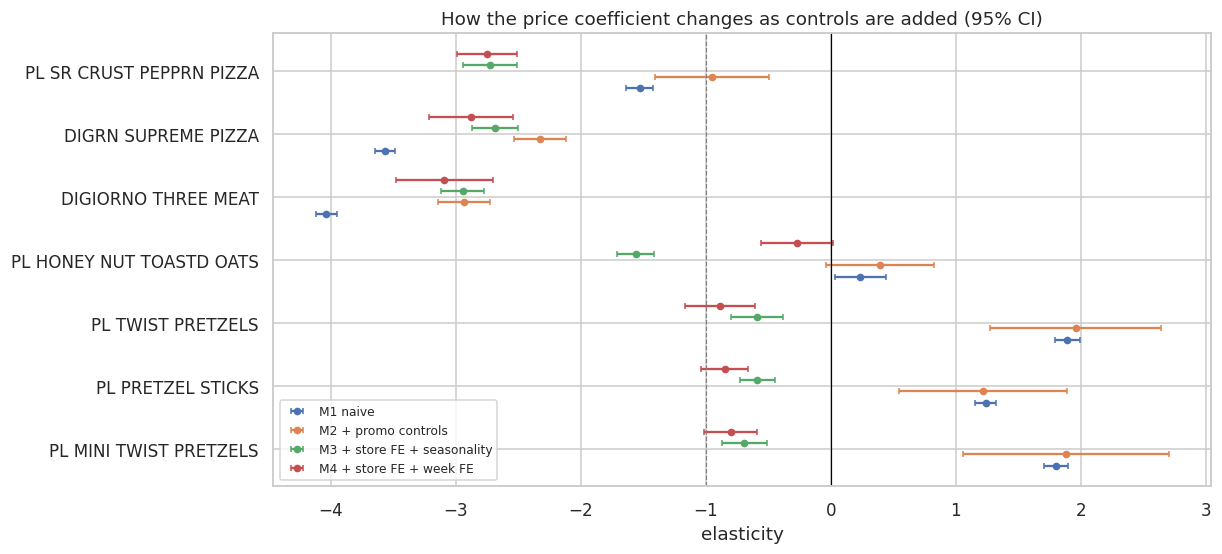

In [8]:
Image(filename=str(config.FIG_DIR / "el_ladder.png"))

**What the ladder shows**
* **M1 → M2:** adding feature and display makes most elasticities *less* negative. Part of the naive "price effect" was really the ad and display effect.
* **Private-label pretzels:** M1 is *positive*, then negative under M3/M4. Stores with higher private-label prices sell more of it
  (store-level confounding). Comparing each store only with itself fixes the sign.
* **M3 → M4:** week fixed effects remove chain-wide shocks. For some products (e.g. Frescetta pizzas) the elasticity drops a lot in
  magnitude. Much of their price variation was chain-wide promotion timing, which coincided with high-demand weeks.
* A few small products (Mike-sell's pretzels, sold in few stores) end up with **positive** controlled estimates. With so little
  independent variation left after fixed effects, the estimate is noise or residual confounding. They must not drive pricing.

## 4. Regular-price vs temporary-discount elasticity (M5)

In [9]:
m5 = ladder[ladder.spec.str.startswith("M5")].pivot_table(index="description", columns="spec", values="elasticity")
m5.columns = ["regular", "temporary discount"]
m5.describe().round(2)

,regular,temporary discount
count,52.0000,52.0000
mean,-1.2000,-1.0900
std,1.1000,0.9800
min,-3.1300,-3.1200
25%,-1.8200,-1.6000
50%,-1.1200,-0.9200
75%,-0.7200,-0.7000
max,2.5300,2.2600


**Observation (contrary to the textbook expectation).** Theory and many studies suggest that consumers react more strongly to temporary
deals than to permanent changes, because deals trigger stockpiling. Here, after controlling for feature, display and week effects, the
temporary-discount coefficient is slightly **smaller** in magnitude than the regular-price coefficient. Plausible reasons: (1) the feature and
display dummies and the week fixed effects already absorb much of the promotional response; (2) shoppers anticipate the frequent
deals, and deal weeks partly shift purchases in time rather than create them; (3) regular-price changes are rarer, so their estimates are noisier
(larger SEs). We do not force the theory onto the data. It also means the response to temporary cuts, which the decision model in section 7
uses, is not inflated relative to regular-price changes here.

## 5. Category-level pooled estimates (for comparison)
One common slope per category, with **store × product** and **product × week** fixed effects (each product keeps its own seasonality).
Pooling trades bias for variance: the estimate is much more precise but assumes the products in a category respond similarly.
The decision model does not use pooling; it uses *partial* pooling (shrinkage, section 8), which sits between "each product alone" and "one slope per category".

In [10]:
pooled

,category,spec,elasticity,se,ci_low,ci_high,p_value,r2,n,n_products
0,BAG SNACKS,pooled shelf-price,-0.5211,0.0436,-0.6065,-0.4357,0.0000,0.0478,127459,15
1,BAG SNACKS,pooled regular-price,-0.8182,0.0582,-0.9323,-0.7042,0.0000,0.0504,127459,15
2,COLD CEREAL,pooled shelf-price,-1.3393,0.0462,-1.4298,-1.2487,0.0000,0.0954,169687,15
3,COLD CEREAL,pooled regular-price,-1.4316,0.0553,-1.5400,-1.3231,0.0000,0.0955,169687,15
4,FROZEN PIZZA,pooled shelf-price,-2.0970,0.2286,-2.5451,-1.6490,0.0000,0.0783,111264,12
5,FROZEN PIZZA,pooled regular-price,-2.4257,0.1566,-2.7326,-2.1189,0.0000,0.0801,111264,12
6,ORAL HYGIENE PRODUCTS,pooled shelf-price,-0.9951,0.0519,-1.0968,-0.8934,0.0000,0.0255,116516,13
7,ORAL HYGIENE PRODUCTS,pooled regular-price,-1.0222,0.0653,-1.1502,-0.8942,0.0000,0.0255,116516,13


## 6. Robustness: excluding flagged outliers

In [11]:
rob = pd.read_csv(R / "elasticity_ladder_no_outliers.csv")
cmp_ = ladder[ladder.spec == "M5 regular-price elasticity"][["description", "elasticity"]].merge(
    rob[rob.spec == "M5 regular-price elasticity"][["description", "elasticity"]], on="description", suffixes=("_all", "_no_outliers"))
print("correlation:", round(cmp_[["elasticity_all", "elasticity_no_outliers"]].corr().iloc[0, 1], 3),
      "| median abs change:", round((cmp_.elasticity_all - cmp_.elasticity_no_outliers).abs().median(), 3))

correlation: 0.964 | median abs change: 0.004


## 7. Promotion-based identification: using promotions *against* confounding
Sections 3-6 *controlled* for promotions. Here promotions become the **source of identifying variation**, in two ways.

### M6/M8: temporary-price-reduction (TPR) events
Restrict the sample to weeks with **no promotion** or a **pure price cut without feature ad or display**. The price variation that
remains is a price cut that is *not* bundled with advertising or extra shelf space, so the ad/display confound is removed by design.

**M8 (the decision model)** adds:
* **store FE**, to remove permanent store differences;
* **week FE**, to remove every chain-wide shock, *including the chain's own promotion timing*. The elasticity is then identified by
  **stores running different temporary discounts in the same week**;
* log(base price) as a separate regressor, so the coefficient of interest is the response to a *temporary* price change;
* last week's discount, to control for pantry loading (the post-promotion dip).

### M7: promotion-calendar instrumental variable (tested and rejected)
Promotions are set centrally: about 74% of discount-depth variance is chain-wide. So a store's price can be instrumented with the
average discount of the same product in the **other** stores that week.

In [12]:
prom = pd.read_csv(R / "promo_identified_elasticities.csv")
lad_w = ladder.pivot_table(index="description", columns="spec", values="elasticity")
prom_w = prom.pivot_table(index="description", columns="spec", values="elasticity")
cmp7 = lad_w[["M1 naive", "M4 + store FE + week FE"]].join(prom_w)
display(cmp7.round(2))
summ = prom.groupby("spec").agg(median=("elasticity", "median"), share_negative=("elasticity", lambda s: (s < 0).mean()),
                                median_se=("se", "median"))
iv = prom[prom.spec.str.startswith("M7")]
print("IV first-stage F: median", round(iv.first_stage_F.median()), "| weak (F<10):", int((iv.first_stage_F < 10).sum()))
summ

spec,M1 naive,M4 + store FE + week FE,M6 TPR-only (no ad/display weeks),M7 promotion-calendar IV,"M8 promotion-identified (TPR events, store+week FE)"
description,,,,,
ACT KIDS BBLGUM FLUOR RNS,-0.9600,-0.6300,-0.6300,-1.8500,-0.5700
ACT MINT A/CAV FLUOR RNS,-1.4400,-0.2600,-0.2600,-1.6600,-0.4000
ACT RSTR CL SPLSH MINT MW,-0.9400,-0.7300,-0.7400,-0.9900,-0.7500
COLG SPEARMINT WISP,-0.2200,-0.2700,-0.2700,-0.6700,-0.2700
CREST PH CLN MINT RINSE,-1.3000,-1.3700,-1.2900,-1.3500,-1.2600
CREST PH WHTG CLN MINT TP,-2.2000,-0.9200,-0.9100,-2.0500,-0.8700
DIGIORNO THREE MEAT,-4.0400,-3.0900,-2.5900,-3.2800,-2.2500
DIGRN PEPP PIZZA,-3.3100,-2.4800,-1.8200,-2.8800,-1.6900
DIGRN SUPREME PIZZA,-3.5700,-2.8800,-2.1800,-2.8500,-2.0200


IV first-stage F: median 1920 | weak (F<10): 3


,median,share_negative,median_se
spec,,,
M6 TPR-only (no ad/display weeks),-0.8676,0.9273,0.1776
M7 promotion-calendar IV,-2.0530,0.9455,0.1333
"M8 promotion-identified (TPR events, store+week FE)",-0.8377,0.8909,0.1945


**Why the IV was rejected.** The instrument is *strong* (median first-stage F in the thousands), but its median elasticity (≈ −2.05) is
almost identical to the **naive** OLS (≈ −2.07). For Frescetta pizzas it gives about −3.4 to −4.0, while the fully controlled model gives about −0.8.
A valid instrument should *remove* confounding, not reproduce it. The exclusion restriction fails: the chain **schedules promotions into
high-demand weeks**, so the promotion calendar is itself correlated with demand. A strong instrument is not necessarily a valid one.
Section 9 confirms this on held-out data, where the IV predicts worse than ignoring price altogether.

M8 avoids this problem because its week fixed effects absorb the chain's promotion timing; only *cross-store* differences in the same week
identify the elasticity. Its median (≈ −0.84) is close to the fully controlled OLS (M4 ≈ −0.93), as expected if confounding has been removed.

## 8. Product-level estimates for every product: empirical-Bayes shrinkage
Some products have few TPR events, so their raw estimates are noisy (e.g. Mike-sell's Mini Twist +2.55 ± 0.89). Instead of replacing them with a
category average, each product estimate is **shrunk** toward its category mean in proportion to its noise:

$$\hat\beta_i^{shrunk} = \mu_c + \frac{\tau^2}{\tau^2 + se_i^2}(\hat\beta_i - \mu_c)$$

where $\tau^2$ is the estimated true spread of elasticities within the category (DerSimonian-Laird). Precise estimates hardly move and noisy ones
borrow strength from the category, so **every product keeps its own product-level estimate**.

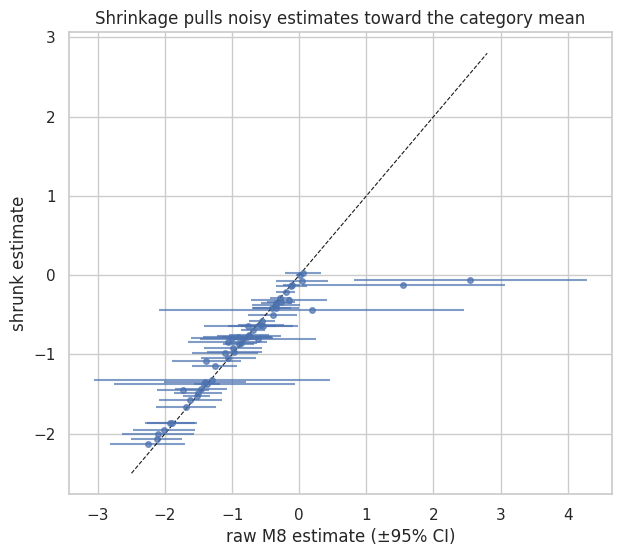

,description,category,elasticity_raw,se_raw,n_tpr_weeks,elasticity,se,category_mean,tau,usable
33,DIGIORNO THREE MEAT,FROZEN PIZZA,-2.2550,0.2850,965.0000,-2.1300,0.2650,-1.3310,0.7220,True
15,QKER LIFE ORIGINAL,COLD CEREAL,-2.1240,0.1950,"1,140.0000",-2.0620,0.1890,-0.9880,0.8110,True
40,NWMN OWN 4 CHEESE PIZZA,FROZEN PIZZA,-2.1080,0.2750,226.0000,-2.0090,0.2570,-1.3310,0.7220,True
34,DIGRN SUPREME PIZZA,FROZEN PIZZA,-2.0170,0.2340,883.0000,-1.9520,0.2230,-1.3310,0.7220,True
17,KELL FROOT LOOPS,COLD CEREAL,-1.9210,0.1910,574.0000,-1.8720,0.1860,-0.9880,0.8110,True
38,PL SR CRUST PEPPRN PIZZA,FROZEN PIZZA,-1.9010,0.1890,"1,236.0000",-1.8650,0.1830,-1.3310,0.7220,True
35,DIGRN PEPP PIZZA,FROZEN PIZZA,-1.6920,0.2280,888.0000,-1.6590,0.2170,-1.3310,0.7220,True
22,QKER CAP N CRUNCH,COLD CEREAL,-1.6260,0.2400,732.0000,-1.5750,0.2300,-0.9880,0.8110,True
18,POST FRUITY PEBBLES,COLD CEREAL,-1.5290,0.1020,668.0000,-1.5210,0.1010,-0.9880,0.8110,True
37,PL SR CRUST SUPRM PIZZA,FROZEN PIZZA,-1.5030,0.1820,"1,273.0000",-1.4930,0.1770,-1.3310,0.7220,True


In [13]:
shr = pd.read_csv(R / "product_elasticity_shrinkage.csv")
fig, ax = plt.subplots(figsize=(7, 6))
ax.errorbar(shr.elasticity_raw, shr.elasticity, xerr=1.96 * shr.se_raw, fmt="o", ms=4, alpha=0.7)
lim = [-2.5, 2.8]; ax.plot(lim, lim, "k--", lw=0.8)
ax.set(xlabel="raw M8 estimate (±95% CI)", ylabel="shrunk estimate", title="Shrinkage pulls noisy estimates toward the category mean")
plt.show()
shr[["description", "category", "elasticity_raw", "se_raw", "n_tpr_weeks", "elasticity", "se", "category_mean", "tau", "usable"]].sort_values("elasticity").round(3)

Four products still have no clearly negative response after shrinkage (shrunk elasticity ≥ −0.1). The engine **does not price them**; it keeps
the current price and flags them for a controlled test, rather than act on an estimate it cannot trust.

## 9. Store-segment elasticities
The dynamic engine prices each product separately for **value, mainstream and upscale stores**. Segment deviations are estimated with
interactions in M8, then shrunk toward 0 across the products of a category.

In [14]:
segd = pd.read_csv(R / "segment_elasticity.csv")
print("significant raw segment deviations (|t| > 2):",
      int(((segd.deviation / segd.deviation_se.replace(0, np.nan)).abs() > 2).sum()), "of",
      int(((segd.segment != "MAINSTREAM") & segd.estimated).sum()), "estimated")
segd.groupby(["category", "segment"]).agg(raw_deviation=("deviation", "median"), shrunk_deviation=("deviation_shrunk", "median"),
                                          segment_elasticity=("segment_elasticity", "median")).round(3)

significant raw segment deviations (|t| > 2): 18 of 93 estimated


raw_deviation  shrunk_deviation  segment_elasticity
category              segment                                                        
BAG SNACKS            MAINSTREAM         0.0000            0.0000             -0.4430
                      UPSCALE            0.1210            0.0260             -0.4170
                      VALUE              0.0000            0.0000             -0.4400
COLD CEREAL           MAINSTREAM         0.0000            0.0000             -1.0510
                      UPSCALE            0.1650            0.0330             -1.0290
                      VALUE              0.0000            0.0000             -1.1110
FROZEN PIZZA          MAINSTREAM         0.0000            0.0000             -1.4340
                      UPSCALE            0.1250            0.0290             -1.4050
                      VALUE              0.1270            0.0510             -1.4310
ORAL HYGIENE PRODUCTS MAINSTREAM         0.0000            0.0000             -0.7600
                      UPSCALE           -0.0580           -0.0120             -0.7620
                      VALUE              0.0570            0.0500             -0.5740

Segment differences exist (upscale stores tend to be less price-sensitive), but after shrinkage they are **modest adjustments** of a few
hundredths to a tenth. The data does not support large store-specific price differences.

## 10. Out-of-sample check (details in notebook 04)
All models were re-estimated on **2009-2010 only** and scored on **17,842 real 2011 price-cut events** (a store cuts the price without ad or display).
The calibration slope regresses the observed lift on the predicted lift; 1.0 means the model gets the *magnitude* right.

In [15]:
pd.read_csv(R / "price_response_validation.csv").round(3)

,model,MAE_within_week,MAE_skill_within_week,calibration_slope,MAE_simple,MAE_skill_simple,n_events
0,No price effect (E = 0),0.4830,0.0000,NaN,0.5060,0.0000,17842
1,M1 naive OLS,0.4750,0.0170,0.3880,0.4680,0.0760,17842
2,M4 controlled OLS (store + week FE),0.4460,0.0780,0.8490,0.4540,0.1040,17842
3,M5 regular-price OLS,0.4470,0.0740,0.7540,0.4580,0.0950,17842
4,M7 promotion-calendar IV,0.5890,-0.2180,0.0850,0.5810,-0.1480,17842
5,M8 promotion-identified (raw),0.4560,0.0570,0.6500,0.4620,0.0870,17842
6,M8 + shrinkage (product level),0.4550,0.0590,1.0210,0.4620,0.0870,17842
7,M8 + shrinkage + store segment (ENGINE),0.4540,0.0600,1.0330,0.4620,0.0870,17842


* The engine's elasticities (M8 + shrinkage) are the **best calibrated** (slope ≈ 1.0): their predicted lifts have the right size.
* The naive OLS overstates the response about 2.5× (slope ≈ 0.39).
* The IV is **worse than assuming no price effect**, which confirms the diagnosis in section 7.
* Controlled OLS (M4) has slightly better MAE skill but under-calibrated magnitudes (0.85). Both are reasonable; M8 is used because it
  isolates price from advertising by design and measures the kind of temporary price move the dynamic engine makes.

## 11. Final elasticity table (decision elasticities)

In [16]:
info = var[["upc", "n_obs", "mean_price", "mean_units"]]
final = sel.merge(info, on="upc")  # decision table already carries raw estimate, SE and TPR event count
final.assign(ci_low=final.elasticity - 1.96 * final.se, ci_high=final.elasticity + 1.96 * final.se)[
    ["description", "category", "n_obs", "n_tpr_weeks", "mean_price", "mean_units", "elasticity_raw", "elasticity", "se",
     "ci_low", "ci_high", "source"]].sort_values("elasticity").round(3)

,description,category,n_obs,n_tpr_weeks,mean_price,mean_units,elasticity_raw,elasticity,se,ci_low,ci_high,source
33,DIGIORNO THREE MEAT,FROZEN PIZZA,11796,965.0000,5.9710,11.8790,-2.2550,-2.1300,0.2650,-2.6500,-1.6110,"product (promotion-identified, shrunk)"
15,QKER LIFE ORIGINAL,COLD CEREAL,10232,"1,140.0000",2.7400,16.8380,-2.1240,-2.0620,0.1890,-2.4330,-1.6910,"product (promotion-identified, shrunk)"
40,NWMN OWN 4 CHEESE PIZZA,FROZEN PIZZA,3807,226.0000,6.0100,6.7240,-2.1080,-2.0090,0.2570,-2.5130,-1.5050,"product (promotion-identified, shrunk)"
34,DIGRN SUPREME PIZZA,FROZEN PIZZA,11918,883.0000,5.9790,16.0670,-2.0170,-1.9520,0.2230,-2.3890,-1.5150,"product (promotion-identified, shrunk)"
17,KELL FROOT LOOPS,COLD CEREAL,11948,574.0000,2.9310,38.3860,-1.9210,-1.8720,0.1860,-2.2360,-1.5080,"product (promotion-identified, shrunk)"
38,PL SR CRUST PEPPRN PIZZA,FROZEN PIZZA,11836,"1,236.0000",3.6010,15.3190,-1.9010,-1.8650,0.1830,-2.2240,-1.5060,"product (promotion-identified, shrunk)"
35,DIGRN PEPP PIZZA,FROZEN PIZZA,11961,888.0000,5.9820,21.7000,-1.6920,-1.6590,0.2170,-2.0850,-1.2340,"product (promotion-identified, shrunk)"
22,QKER CAP N CRUNCH,COLD CEREAL,10493,732.0000,2.4790,23.9430,-1.6260,-1.5750,0.2300,-2.0260,-1.1230,"product (promotion-identified, shrunk)"
18,POST FRUITY PEBBLES,COLD CEREAL,10094,668.0000,2.5570,28.8000,-1.5290,-1.5210,0.1010,-1.7190,-1.3220,"product (promotion-identified, shrunk)"
37,PL SR CRUST SUPRM PIZZA,FROZEN PIZZA,11648,"1,273.0000",3.5870,12.1570,-1.5030,-1.4930,0.1770,-1.8390,-1.1460,"product (promotion-identified, shrunk)"


## 12. Why these are still not proven causal effects
* **Residual confounding:** a store's discount could still react to *local* demand (store-week shocks are not absorbed by store or week FE).
* **Temporary vs permanent:** M8 measures the response to temporary price cuts, which can include stockpiling and deal-seeking. The engine
  also uses it for price *increases*, which assumes the response is symmetric. Notebook 04 shows the magnitudes are right for cuts on held-out
  data; increases are an extrapolation.
* **Selection:** zero-sales weeks are missing (stockout vs zero demand).
* **Constant elasticity** within ±20%; **no cross-price effects** (cannibalisation).

Promotion-based variation *reduces* confounding; it does not remove it. A randomised store-level price test would.